# CODE 4.1: Train Isolation Forest

> **Goal:** train the first model, Isolation Forest, on the healthy February windows, and see how it scores February and March.
>
> - **Input:** `data/processed/windows.parquet` (3.1) and `results/time_split.csv` (1.2).
> - **Output:** `models/isolation_forest.joblib` (the trained model) and `results/signals_used.json` (the signals both models use). At the end you should see **ALL CHECKS PASSED**.
>
> The test windows (April to August) are dropped right after loading. They get their scores only in notebook 5.2, after the alarm rules are locked in notebook 5.1.

### How Isolation Forest Works

> Think of a class photo with 256 students. You want to point out one student, but you may only draw straight lines across the photo, at random places. After each line you keep the side where your student stands and draw the next line there. A student in the middle of the crowd needs many lines before standing alone. A student standing far away from the others is alone after one or two lines.
>
> Isolation Forest plays this game with windows. A **tree** keeps cutting a group of 256 February windows. Each cut picks one summary number at random, and a random value between its smallest and largest value in the group. The number of cuts needed to get a window alone is its **path length**:
>
> - **few cuts:** the window is easy to separate from the healthy ones, so it is **unusual**;
> - **many cuts:** it hides in the crowd, so it looks **normal**.
>
> One tree can be lucky or unlucky, so the **forest** grows many trees and averages the number of cuts. Scikit-learn turns this average into a score between 0 and 1, as in the original paper (Liu, Ting and Zhou, 2008): close to 1 means very unusual, around 0.5 or lower means normal. Scikit-learn's `score_samples()` gives this score with a minus sign (lower = more unusual), so we flip the sign: in this project **a higher score always means more unusual**.
>
> Two useful side effects:
>
> - **No scaling needed.** A cut is placed between the smallest and the largest value of one number, so it does not matter whether that number is in bar, °C or a count.
> - **Healthy data only.** The forest only sees February. Anything that is easy to cut away from February looks unusual to it.

### Decision: 12 of the 15 Signals

> Notebook 3.2 found three on/off signals that never change in February: `LPS`, `Oil_level` and `Caudal_impulses`. After notebook 3.2 we decided to leave them out of **both** models:
>
> - A model learns what "normal" looks like from February. A signal that never moves in February teaches it nothing.
> - Isolation Forest cannot use them anyway: a cut needs a number with at least two different values.
> - The LSTM would learn "this signal is always the same" and react to every change in it, also when the change may have nothing to do with a leak, for example `Caudal_impulses` in early March.
> - Little is lost: `LPS` only says "the pressure is below 7 bar", and the pressures themselves stay in the data (`TP3`, `Reservoirs`, `H1`).
>
> The rule uses February only: **a signal whose summary numbers never change in the train month is left out.** This notebook applies the rule and saves the signals that are left, so that notebook 4.2 gives the LSTM exactly the same signals.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`: folders, file paths, and the small file with the signal list.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts.
> - `IsolationForest` from `scikit-learn`: the model.
> - `spearmanr` from `scipy`: measures how similar the order of two lists of scores is.
> - `joblib`: saves and loads the trained model. A joblib file can run code when it is loaded, so only load model files you made yourself.

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import IsolationForest
from scipy.stats import spearmanr

### Variables

#### Folder Paths

> The inputs from notebooks 1.2 and 3.1, and the two files this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
MODEL_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `SIGNALS`: the 15 signals, in the order of notebook 3.1. `WINDOW_INFO`: the columns of `windows.parquet` that are not summary numbers.
> - `N_TREES`: how many trees the forest grows. More trees give steadier scores; a check near the end trains a second forest to see how steady they are.
> - `MAX_SAMPLES`: each tree is grown on this many random February windows, the group size used in the original paper. A small group makes the unusual windows easier to cut away.
> - `SEED`: fixes the random cuts, so every run gives the same forest. `SECOND_SEED`: a second forest with other random cuts, used only for the steadiness check.
> - `DEMO_FEATURES`, `DEMO_POINTS`, `DEMO_TREES`, `DEMO_MARCH_END`: the small hand-made example in "See the Idea First".
> - `PUSH_FACTORS`: how far we push one window away from February in "The Score Has a Ceiling".
> - `HALF_OF_MARCH`: splits March into two halves, as in notebook 3.2.
> - `TOP_WINDOWS`, `TOP_COLUMNS`: how many of the most unusual March windows we list, and which of their summary numbers we show.
> - `MIN_RANK_AGREEMENT`: the lowest agreement we accept between the two forests.

In [3]:
ANALOG_COLUMNS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs", "Oil_temperature", "Motor_current"]
DIGITAL_COLUMNS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS", "Pressure_switch", "Oil_level", "Caudal_impulses"]
SIGNALS = ANALOG_COLUMNS + DIGITAL_COLUMNS
WINDOW_INFO = ["end", "start", "end_index", "split"]

N_TREES = 300
MAX_SAMPLES = 256
SEED = 0
SECOND_SEED = 1

DEMO_FEATURES = ["drop_bar_per_min", "rise_bar_per_min"]
DEMO_POINTS = 256
DEMO_TREES = 500
DEMO_MARCH_END = "2020-03-29 12:00:00"
PUSH_FACTORS = [2, 5, 10]
HALF_OF_MARCH = "2020-03-16 00:00:00"
TOP_WINDOWS = 10
TOP_COLUMNS = ["pump_starts", "drop_bar_per_min", "rise_bar_per_min", "TP3_min", "Oil_temperature_std"]
MIN_RANK_AGREEMENT = 0.95

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Cut One Window Out, by Hand

> `isolate()` plays the class-photo game with two summary numbers, so that we can draw it:
>
> 1. Pick one of the two numbers at random (only a number that still has different values in the group).
> 2. Pick a random value between its smallest and largest value in the group, and cut there.
> 3. Keep the side where the target window is, and repeat until the target is alone.
>
> It returns every cut, with the box it was drawn in: `[left, right, bottom, top]`.

In [5]:
def isolate(points, target, rng):
    inside = np.ones(len(points), dtype=bool)
    box = [points[:, 0].min(), points[:, 0].max(), points[:, 1].min(), points[:, 1].max()]
    cuts = []
    while inside.sum() > 1:
        movable = [axis for axis in [0, 1] if points[inside, axis].min() < points[inside, axis].max()]
        if not movable:
            break
        axis = int(rng.choice(movable))
        value = rng.uniform(points[inside, axis].min(), points[inside, axis].max())
        cuts.append({"axis": axis, "value": value, "box": list(box)})
        keep_low = points[target, axis] < value
        inside &= (points[:, axis] < value) if keep_low else (points[:, axis] >= value)
        box[2 * axis + (1 if keep_low else 0)] = value
    return cuts

### Score Windows

> `anomaly_score()` returns the score of each window: scikit-learn's `score_samples()` with the sign flipped, so that a higher score means more unusual.

In [6]:
def anomaly_score(model, features):
    return -model.score_samples(features)

## Load the Windows

### Read the Windows and Drop the Test Months

> We read the windows of notebook 3.1 and keep only train (February) and validation (March). The test windows are dropped here, before anything else happens.

In [7]:
df_windows = pd.read_parquet(WINDOWS_FILE)
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
validation_from = pd.Timestamp(split_table.loc["validation", "from"])
windows_in_file = len(df_windows)
df_windows = df_windows[df_windows["split"].isin(["train", "validation"])].reset_index(drop=True)
ALL_FEATURES = [column for column in df_windows.columns if column not in WINDOW_INFO]
is_train, is_march = df_windows["split"] == "train", df_windows["split"] == "validation"

print(f"Windows in the file: {windows_in_file:,} | kept: {len(df_windows):,} (February {is_train.sum():,}, March {is_march.sum():,})")
print("Summary numbers per window:", len(ALL_FEATURES))
check("only February and March windows are kept", set(df_windows["split"].unique()) <= {"train", "validation"})

Windows in the file: 47,491 | kept: 13,984 (February 6,790, March 7,194)
Summary numbers per window: 46
PASS  only February and March windows are kept


## Choose the Inputs

### Signals That Never Change in February

> We look for summary numbers that have one single value in all February windows, and find the signals they belong to. Then we keep every summary number that does not belong to one of these signals.

In [8]:
february = df_windows.loc[is_train, ALL_FEATURES]
never_changes = [column for column in ALL_FEATURES if february[column].nunique() == 1]
dropped_signals = [signal for signal in SIGNALS if f"{signal}_on_share" in never_changes]
signals_used = [signal for signal in SIGNALS if signal not in dropped_signals]
FEATURE_COLUMNS = [column for column in ALL_FEATURES if not column.startswith(tuple(f"{signal}_" for signal in dropped_signals))]

display(pd.DataFrame({"value in every February window": february[never_changes].iloc[0]}))
print("Signals left out:", dropped_signals)
print(f"Signals kept: {len(signals_used)} of {len(SIGNALS)} | summary numbers kept: {len(FEATURE_COLUMNS)} of {len(ALL_FEATURES)}")
check("the numbers that never change in February are exactly the numbers of the left-out signals",
      set(never_changes) == {f"{signal}_{kind}" for signal in dropped_signals for kind in ["on_share", "switches"]})

,value in every February window
LPS_on_share,0.0
LPS_switches,0.0
Oil_level_on_share,1.0
Oil_level_switches,0.0
Caudal_impulses_on_share,1.0
Caudal_impulses_switches,0.0


Signals left out: ['LPS', 'Oil_level', 'Caudal_impulses']
Signals kept: 12 of 15 | summary numbers kept: 40 of 46
PASS  the numbers that never change in February are exactly the numbers of the left-out signals


> **What we see:** six summary numbers have one single value in all of February, and they are exactly the on-share and the switches of the three signals. The forest gets the summary numbers that are left; the LSTM in notebook 4.2 gets the signals that are left.

## See the Idea First

### Cutting One Window Out, by Hand

> Before we train the real forest, we play the class-photo game with only two summary numbers, so that every cut can be drawn:
>
> - `drop_bar_per_min`: how fast the tank pressure drops while the pump rests.
> - `rise_bar_per_min`: how fast the tank pressure rises while the pump runs.
>
> The group holds random February windows plus one target window. We try two targets:
>
> - **a normal February window:** the one closest to the February middle values of the two numbers;
> - **a March window without a pump break:** the window ending at `DEMO_MARCH_END`, in the longest stretch of pumping without a break from notebook 3.2.
>
> For each target we draw one tree, and then count the cuts again in many trees.

Group: 255 random February windows + 1 target window
A normal February window (24 Feb 17:55): 19 cuts in the tree drawn below, 14.8 cuts on average over 500 trees
A March window without a pump break (29 Mar 12:00): 1 cut in the tree drawn below, 2.0 cuts on average over 500 trees


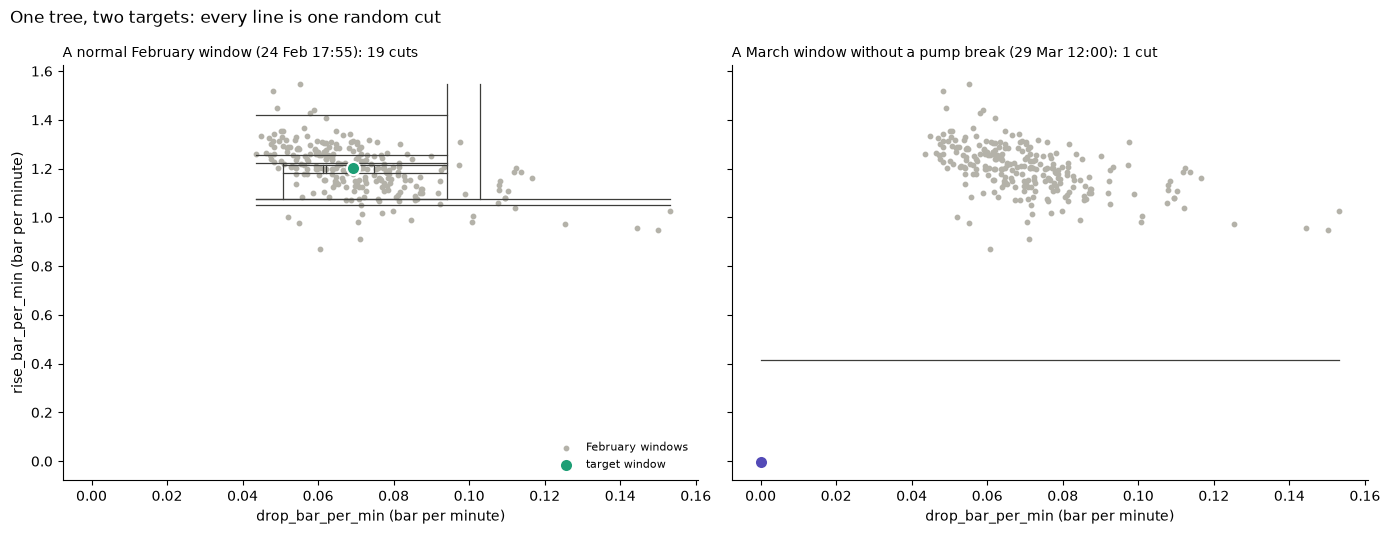

PASS  the March window without a pump break needs fewer cuts on average than the normal window


In [9]:
rng = np.random.default_rng(SEED)
february_points = february[DEMO_FEATURES].to_numpy(dtype="float64")
distance = (((february_points - np.median(february_points, axis=0)) / february_points.std(axis=0)) ** 2).sum(axis=1)
normal_index = int(np.argmin(distance))
normal_end = df_windows.loc[is_train, "end"].iloc[normal_index]
march_point = df_windows.loc[df_windows["end"] == pd.Timestamp(DEMO_MARCH_END), DEMO_FEATURES].to_numpy(dtype="float64")
others = rng.choice(np.delete(np.arange(len(february_points)), normal_index), size=DEMO_POINTS - 1, replace=False)
target = DEMO_POINTS - 1
demo = [(f"A normal February window ({normal_end:%d %b %H:%M})", np.vstack([february_points[others], february_points[[normal_index]]]), "#1D9E75"),
        (f"A March window without a pump break ({pd.Timestamp(DEMO_MARCH_END):%d %b %H:%M})", np.vstack([february_points[others], march_point]), "#534AB7")]

print(f"Group: {DEMO_POINTS - 1} random February windows + 1 target window")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharex=True, sharey=True)
averages = []
for ax, (title, points, color) in zip(axes, demo):
    drawn = isolate(points=points, target=target, rng=np.random.default_rng(SEED))
    tree_rng = np.random.default_rng(SECOND_SEED)
    averages.append(np.mean([len(isolate(points=points, target=target, rng=tree_rng)) for _ in range(DEMO_TREES)]))
    ax.scatter(points[:-1, 0], points[:-1, 1], s=10, color="#B4B2A9", label="February windows")
    for cut in drawn:
        left, right, bottom, top = cut["box"]
        xs, ys = ([cut["value"]] * 2, [bottom, top]) if cut["axis"] == 0 else ([left, right], [cut["value"]] * 2)
        ax.plot(xs, ys, color="#3D3D3A", linewidth=0.9)
    ax.scatter(points[target, 0], points[target, 1], s=90, color=color, edgecolor="white", linewidth=1.5, zorder=3, label="target window")
    cut_words = f"{len(drawn)} cut" if len(drawn) == 1 else f"{len(drawn)} cuts"
    ax.set_title(f"{title}: {cut_words}", fontsize=10, loc="left")
    ax.set_xlabel("drop_bar_per_min (bar per minute)")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    print(f"{title}: {cut_words} in the tree drawn below, {averages[-1]:.1f} cuts on average over {DEMO_TREES} trees")
axes[0].set_ylabel("rise_bar_per_min (bar per minute)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("One tree, two targets: every line is one random cut", x=0.01, ha="left")
plt.tight_layout()
plt.show()

check("the March window without a pump break needs fewer cuts on average than the normal window", averages[1] < averages[0])

> **What we see:** the normal February window sits in the middle of the crowd, so the tree needs many cuts to get it alone. The March window sits far away from every February window (the pump never rested, so `drop_bar_per_min` is 0, and the pressure barely rose), so it is alone after very few cuts. Over many trees the difference stays: compare the two averages printed above. The real forest does exactly this, only with all the summary numbers instead of two, and with many trees.

## Train the Forest

### Grow the Trees on February

> The forest learns from the February windows only, with the summary numbers in their real units. We leave `contamination` at its default value: it only matters for scikit-learn's own yes-or-no answer (`predict()`), which we do not use. The alarm limit comes from March, in notebook 5.1.

In [10]:
X_train = df_windows.loc[is_train, FEATURE_COLUMNS]
model = IsolationForest(n_estimators=N_TREES, max_samples=MAX_SAMPLES, random_state=SEED)
model.fit(X_train)

print(f"Trees: {len(model.estimators_)} | February windows per tree: {model.max_samples_} | summary numbers: {model.n_features_in_}")
print(f"Trained on {len(X_train):,} windows, ending from {df_windows.loc[is_train, 'end'].min()} to {df_windows.loc[is_train, 'end'].max()}")
check("the forest learned from February windows only", len(X_train) == is_train.sum() and (df_windows.loc[X_train.index, "end"] < validation_from).all())

Trees: 300 | February windows per tree: 256 | summary numbers: 40
Trained on 6,790 windows, ending from 2020-02-01 01:00:00 to 2020-02-28 23:55:00
PASS  the forest learned from February windows only


### Score February and March

> Every February and March window gets its score. The February windows are the ones the forest learned from, so they are expected to look normal. March is new to the forest.

,count,min,50%,90%,99%,max
split,,,,,,
February,6790.0,0.355,0.425,0.505,0.581,0.735
March,7194.0,0.424,0.610,0.715,0.732,0.756


February windows below the March middle score: 99%
March windows above the highest February score: 45 of 7,194


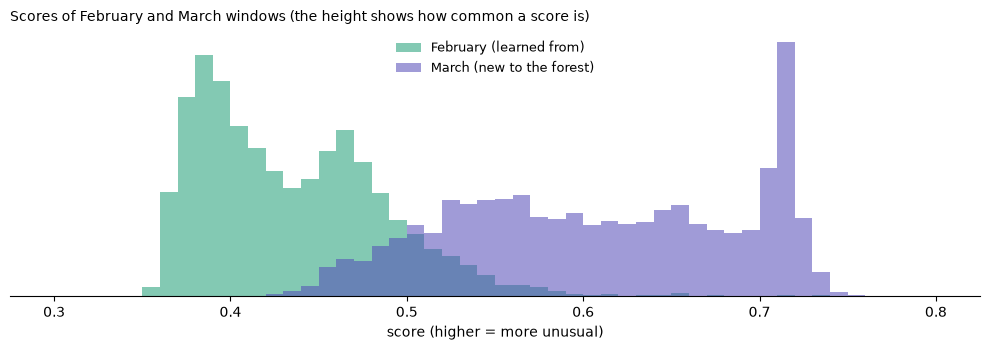

Tallest March bar: scores from 0.71 to 0.72, 787 windows
PASS  every February and March window has a score between 0 and 1


In [11]:
df_windows["score"] = anomaly_score(model=model, features=df_windows[FEATURE_COLUMNS])
february_scores, march_scores = df_windows.loc[is_train, "score"], df_windows.loc[is_march, "score"]

summary = df_windows.groupby("split")["score"].describe(percentiles=[0.5, 0.9, 0.99])[["count", "min", "50%", "90%", "99%", "max"]]
display(summary.rename(index={"train": "February", "validation": "March"}).round(3))
print(f"February windows below the March middle score: {(february_scores < march_scores.median()).mean():.0%}")
print(f"March windows above the highest February score: {(march_scores > february_scores.max()).sum():,} of {len(march_scores):,}")

fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(0.3, 0.8, 51)
ax.hist(february_scores, bins=bins, density=True, alpha=0.55, color="#1D9E75", label="February (learned from)")
ax.hist(march_scores, bins=bins, density=True, alpha=0.55, color="#534AB7", label="March (new to the forest)")
ax.set_xlabel("score (higher = more unusual)")
ax.set_yticks([])
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Scores of February and March windows (the height shows how common a score is)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

march_counts, edges = np.histogram(march_scores, bins=bins)
tallest = int(march_counts.argmax())
print(f"Tallest March bar: scores from {edges[tallest]:.2f} to {edges[tallest + 1]:.2f}, {march_counts[tallest]:,} windows")

check("every February and March window has a score between 0 and 1", np.isfinite(df_windows["score"]).all() and df_windows["score"].between(0, 1).all())

> **What we see:** the February scores sit around their middle value, below 0.5, as the paper describes for normal data. The March scores are shifted clearly to the right: the middle March window scores higher than almost all February windows (see the share printed above). So, to a forest that learned February, much of March already looks unusual. That matches notebook 3.2: in March the oil temperature swings more and the tanks fill more slowly, for the whole month.
>
> Look also at the tallest March bar, just above 0.7 (printed above): many quite different March windows get almost the same high score, and only a few March windows score higher than the highest February window. The section "The Score Has a Ceiling" below explains why.

### February and March, Day by Day

> Each dot is one window, placed at its end time. The grey bands are the stretches of pumping without a break that notebook 3.2 found (rebuilt here the same way, from the windows with `drop_bar_per_min` = 0). The dashed line is the highest score of any February window.

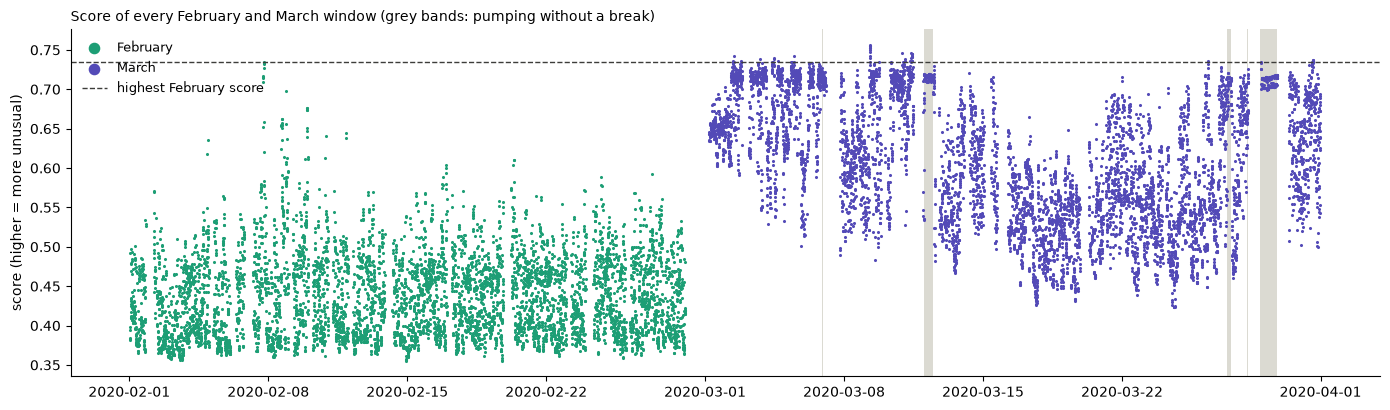

Middle score (median): {'February': 0.425, 'March 1-15': 0.657, 'March 16-31': 0.562, 'March, pumping without a break': 0.714}
Highest score in the stretches without a pump break: 0.734 | highest February score: 0.735


In [12]:
whole_hour = df_windows.loc[is_march & (df_windows["drop_bar_per_min"] == 0)]
new_stretch = whole_hour["end"].diff() != pd.Timedelta(minutes=5)
stretches = whole_hour.groupby(new_stretch.cumsum()).agg(first_end=("end", "min"), until=("end", "max"))
stretches["pumping_from"] = stretches["first_end"] - pd.Timedelta(minutes=60)
first_half = is_march & (df_windows["end"] < pd.Timestamp(HALF_OF_MARCH))
second_half = is_march & (df_windows["end"] >= pd.Timestamp(HALF_OF_MARCH))

fig, ax = plt.subplots(figsize=(14, 4.2))
for row in stretches.itertuples():
    ax.axvspan(row.pumping_from, row.until, color="#D3D1C7", alpha=0.8, linewidth=0)
ax.scatter(df_windows.loc[is_train, "end"], february_scores, s=1.5, color="#1D9E75", label="February")
ax.scatter(df_windows.loc[is_march, "end"], march_scores, s=1.5, color="#534AB7", label="March")
ax.axhline(february_scores.max(), color="#3D3D3A", linestyle="--", linewidth=1, label="highest February score")
ax.set_ylabel("score (higher = more unusual)")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="upper left", markerscale=6)
ax.set_title("Score of every February and March window (grey bands: pumping without a break)", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

middles = pd.Series({"February": february_scores.median(), "March 1-15": df_windows.loc[first_half, "score"].median(),
                     "March 16-31": df_windows.loc[second_half, "score"].median(),
                     "March, pumping without a break": df_windows.loc[whole_hour.index, "score"].median()})
print("Middle score (median):", middles.round(3).to_dict())
print(f"Highest score in the stretches without a pump break: {df_windows.loc[whole_hour.index, 'score'].max():.3f} | highest February score: {february_scores.max():.3f}")

> **What we see:** February stays low, apart from a few short bumps. March starts high: the first half of March, with its extra pumping, sits highest. The second half comes down, but stays above most of February (compare its middle score with the February 90% value in the table above). The hours without a pump break score high too, but none of them goes above the dashed line, and the highest scores of March are elsewhere. The next two sections show which windows score highest, and why the hours without a pump break do not.

### The Most Unusual March Windows

> The March windows with the highest scores, with a few of their summary numbers. The last row shows the middle February value of each number, to compare.

In [13]:
top = df_windows.loc[is_march].nlargest(TOP_WINDOWS, "score")
top_table = top.set_index(top["end"].dt.strftime("%d %b %H:%M"))[["score"] + TOP_COLUMNS]
february_row = pd.DataFrame([[february_scores.median()] + february[TOP_COLUMNS].median().tolist()], columns=["score"] + TOP_COLUMNS, index=["February (median)"])
display(pd.concat([top_table, february_row]).astype("float64").round(3))
print("Days of March in this list:", sorted(top["end"].dt.day.unique().tolist()))
print("Windows of this list in a stretch without a pump break:", int((top["drop_bar_per_min"] == 0).sum()))

,score,pump_starts,drop_bar_per_min,rise_bar_per_min,TP3_min,Oil_temperature_std
09 Mar 06:50,0.756,4.0,0.166,0.496,7.200,5.350
09 Mar 07:00,0.755,5.0,0.202,0.544,7.200,4.931
09 Mar 07:35,0.755,4.0,0.141,0.471,7.200,5.756
09 Mar 06:55,0.753,4.0,0.195,0.496,7.200,5.472
09 Mar 07:05,0.752,4.0,0.192,0.512,7.200,3.762
09 Mar 07:10,0.750,4.0,0.166,0.480,7.200,3.711
09 Mar 07:30,0.748,4.0,0.144,0.674,7.200,5.541
11 Mar 09:30,0.746,4.0,0.159,0.618,7.920,4.044
10 Mar 22:35,0.746,4.0,0.160,0.454,8.118,4.453
11 Mar 09:45,0.745,4.0,0.161,0.621,8.108,4.221


Days of March in this list: [9, 10, 11]
Windows of this list in a stretch without a pump break: 0


> **What we see:** all of these windows come from the first part of March, and none of them is in a stretch without a pump break. In these hours the compressor started 4 or 5 times an hour instead of 2, the pressure dropped faster while resting and rose more slowly while pumping, and the oil temperature swung much more. On 9 March the lowest pressure even fell well below its usual February level. These windows are unusual in many summary numbers at the same time.

### The Score Has a Ceiling

> Why do the hours without a pump break not get the highest scores, although they look so strange? We take the March window ending at `DEMO_MARCH_END`, count how many of its summary numbers lie outside the February range, and score it. Then we push every number 2, 5 and 10 times as far away from its February middle value, and score again.

In [14]:
window = df_windows.loc[df_windows["end"] == pd.Timestamp(DEMO_MARCH_END), FEATURE_COLUMNS].astype("float64")
middle = X_train.median()
outside = int(((window.iloc[0] > X_train.max()) | (window.iloc[0] < X_train.min())).sum())
pushed = pd.DataFrame([middle + factor * (window.iloc[0] - middle) for factor in PUSH_FACTORS], columns=FEATURE_COLUMNS)

print(f"Window ending {DEMO_MARCH_END}: {outside} of {len(FEATURE_COLUMNS)} summary numbers lie outside the February range")
print(f"Score as it is: {anomaly_score(model=model, features=window)[0]:.3f}")
for factor, score in zip(PUSH_FACTORS, anomaly_score(model=model, features=pushed)):
    print(f"Every number pushed {factor} times as far from February: {score:.3f}")

Window ending 2020-03-29 12:00:00: 33 of 40 summary numbers lie outside the February range
Score as it is: 0.703
Every number pushed 2 times as far from February: 0.707
Every number pushed 5 times as far from February: 0.714
Every number pushed 10 times as far from February: 0.720


> **What we see:** the score hardly moves, even when the window is pushed ten times further away.
>
> The reason is how a tree cuts. It only cuts **between February windows**, because February is all it has seen. A window that lies beyond the most extreme February window simply lands next to that February window, whether it is a little beyond or very far beyond. Think of a ruler that ends where February ended: everything past the end of the ruler is measured as "at the end of the ruler".
>
> So Isolation Forest can tell "normal" from "unusual" well, but not "unusual" from "very unusual". The high scores bunch together, and the alarm limit of notebook 5.1 will sit inside this bunch. The LSTM of notebook 4.2 works differently: it measures how badly it can redraw a window, and that error can keep growing. This is one of the differences to compare later.

### Same Settings, Another Seed

> The cuts are random, so a forest with other random cuts (`SECOND_SEED`) gives slightly different scores. What matters for an alarm is the **order** of the windows: which ones are more unusual than others. Spearman's rank agreement compares two orders: 1 means exactly the same order, 0 means no relation.

In [15]:
second_model = IsolationForest(n_estimators=N_TREES, max_samples=MAX_SAMPLES, random_state=SECOND_SEED).fit(X_train)
second_scores = anomaly_score(model=second_model, features=df_windows.loc[is_march, FEATURE_COLUMNS])
agreement = spearmanr(march_scores, second_scores).statistic

print(f"Rank agreement of the March scores, seed {SEED} against seed {SECOND_SEED}: {agreement:.3f}")
print(f"Largest score difference between the two forests in March: {np.abs(march_scores.to_numpy() - second_scores).max():.3f}")
check(f"a second forest orders the March windows almost the same way (agreement at least {MIN_RANK_AGREEMENT})", agreement >= MIN_RANK_AGREEMENT)

Rank agreement of the March scores, seed 0 against seed 1: 0.989
Largest score difference between the two forests in March: 0.045
PASS  a second forest orders the March windows almost the same way (agreement at least 0.95)


> **What we see:** the two forests order the March windows almost the same way, so the results do not depend on lucky cuts. The second forest is not saved; it was only needed for this check.

## Save

### What Will Be Written

> A preview of the two files this notebook writes, and whether they exist already.

In [16]:
for path in [MODEL_FILE, SIGNALS_FILE]:
    print(f"{os.path.relpath(path, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(path) else 'new file'}")

models\isolation_forest.joblib: new file
results\signals_used.json: new file


### Save the Model and the Signal List

> - `models/isolation_forest.joblib`: the trained forest, compressed. Notebooks 5.1 to 5.3 and the dashboard load it.
> - `results/signals_used.json`: the kept signals in the order of the grid (for the LSTM in notebook 4.2), the left-out signals, and the summary numbers of the forest.

In [17]:
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
joblib.dump(model, MODEL_FILE, compress=3)
with open(SIGNALS_FILE, "w", encoding="utf-8") as f:
    json.dump({"signals": signals_used, "left_out": dropped_signals, "isolation_forest_features": FEATURE_COLUMNS}, f, indent=2)

for path in [MODEL_FILE, SIGNALS_FILE]:
    print(f"Saved {os.path.relpath(path, ROOT_DIR)} ({os.path.getsize(path) / 1024:,.0f} KB)")

Saved models\isolation_forest.joblib (917 KB)
Saved results\signals_used.json (1 KB)


### Read the Files Back

> We load both files again, as notebook 4.2 and notebook 5.1 will, and check that nothing was lost.

In [18]:
loaded_model = joblib.load(MODEL_FILE)
with open(SIGNALS_FILE, encoding="utf-8") as f:
    saved_signals = json.load(f)

check("the saved model gives exactly the same scores", np.array_equal(anomaly_score(model=loaded_model, features=df_windows[FEATURE_COLUMNS]), df_windows["score"].to_numpy()))
check("the saved file lists the kept signals in the order of the grid, and the summary numbers of the forest",
      saved_signals["signals"] == [signal for signal in SIGNALS if signal in signals_used] and saved_signals["isolation_forest_features"] == FEATURE_COLUMNS)

PASS  the saved model gives exactly the same scores
PASS  the saved file lists the kept signals in the order of the grid, and the summary numbers of the forest


## Result

### Final Result

> If every check passed, the forest is trained on February only, and the model and the signal list are saved. If a check failed, its name is printed.

In [19]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (8 checks)


## Summary

> - Isolation Forest finds unusual windows by cutting them away from healthy windows: few cuts mean unusual, many cuts mean normal.
> - The three signals that never change in February are left out of both models. The forest uses the summary numbers of the signals that are left, and the signal list is saved for the LSTM in notebook 4.2.
> - Trained on February only, the forest finds much of March unusual. The most unusual windows are in the first half of March, with its extra pumping. The hours without a pump break score high too, but not highest, because the score has a ceiling: the forest cannot tell "unusual" from "very unusual".
> - A second forest with other random cuts orders the March windows almost the same way.
> - Notebook 5.1 sets the alarm limit on March, leaving out the unusual March hours, as decided after notebook 3.2. Because much of March looks a bit unusual to the forest, that limit will be fairly high.
>
> **Next:** `notebooks/4_modeling/4.2_train_lstm_autoencoder.ipynb`